\newpage

I will be investigating the following question: How accurately can historical ozone and PM2.5 concentrations be used to predict their concentrations one hour ahead using tree-based machine learning methods? This question is of interest to me because it would be interesting to compare how different tree-based methods would predict future ozone and PM2.5 concentrations.


One row in the original CSV files represents the Ozone and PM2.5 concentrations for station 29118 over one day from hour 1 to hour 23, such that concentrations of each were measured every hour. One row of my analysis-ready dataset represents the ozone and PM2.5 concentrations for a day at a specific hour, as shown in Table 1 in the supplemental material. To identify missing/invalid observations, I used the original CSV's metadata to see what they labeled as missing, which in this case were values such as 999, -999, and 9999. I replaced those values with NaN's, and then I used linear interpolation to fill in the missing values based on the surrounding data. This was done because the concentrations did not change much from hour to hour, with some exceptions, so it would be unlikely that new patterns would be introduced. I identifed duplicate observations by running code to find any duplicate dates in the original data, and while there were no duplicate values, there were two instances of Feburary 13. Because there were 365 rows, one for each day of the year, and since every other day besides February 14 was present, I assumed that the second instance of February 13 was meant to be February 14. 

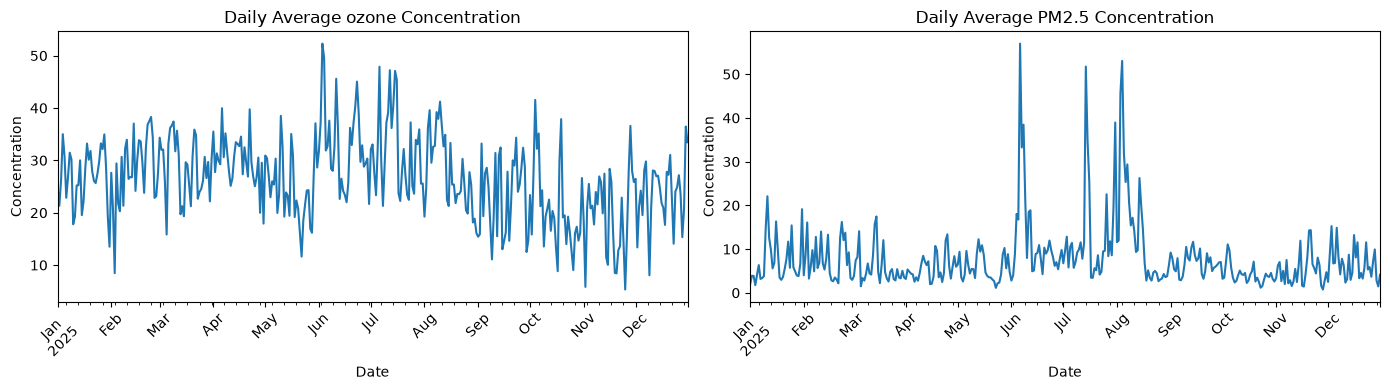

The temporal patterns for both are shown in Figure 1. We can see that daily average Ozone concentration does not fluctuate that much throughout the year but it is slightly higher in June and July and slightly lower in November and December. For PM2.5, we see peaks in June, July, and August while every other day has lower average PM2.5 concentrations.

I used a rolling 24-hour window of historical ozone and PM2.5 concentrations to construct the predictors. Each window contains the current hourly observation and the 23 hourly observations before it. The window moves forward by one hour for each prediction. I chose this window because ozone and PM2.5 concentration can exhibit daily patterns and fluctuate throughout the day, and having it move foward for each prediction lets the predictors capture the conditions over the preceding 24-hour period. For each pollutant, the statistical summary features included the most recent concentration, the average concentration over the previous 24 hours including current hour, and the standard deviation within that 24 hour window. The two FFT features I constructed were the dominant frequency and dominant spectral power. 
The dominant frequency identifies the strongest frequency component within the 24-hour window, indicating the time scale at which the most prominent oscillation occurs. Dominant power measures the strength of this frequency component, indicating how prominent the corresponding oscillation is within the observed measurements. Together, these features provide information about the frequency and strength of fluctuations, complementing the rolling mean and standard deviation, which summarize the overall concentration level and variability.
As mentioned above, the missing measurements were filled in by linear interpolation. To ensure that my predictors contained no future information, the rolling window was constructed such that only the current observation and the preceding 24 hours were used.

::: {layout-ncol=2 fig-subcap=false}
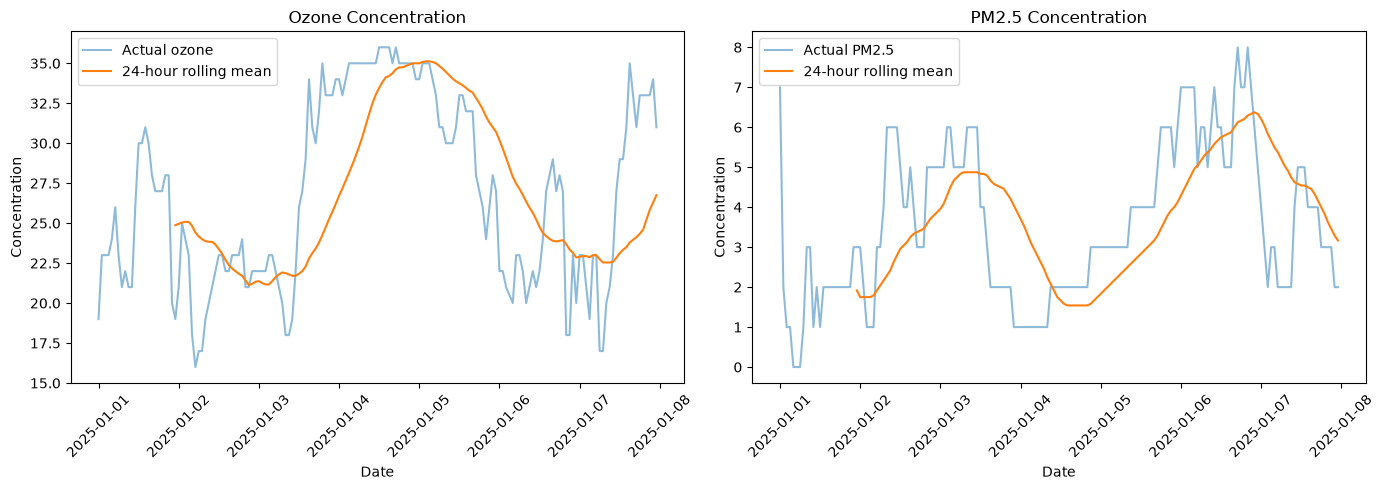

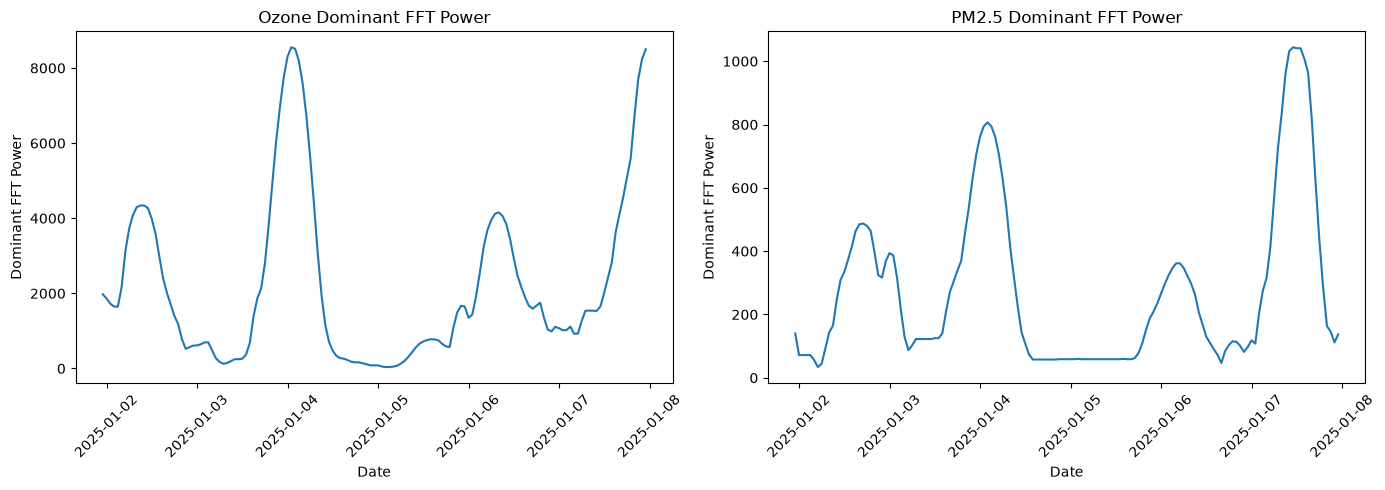
:::

From Figure 2, we see that the rolling mean describes the general movement of the pollutant concentration values. In Figure 3, we can see that the graph shows us how the intensity of fluctuations differ each day throughout the week.

Observations from January to September were used as the training set, and observations from October to December were used as the test set. I chose this divide because this way, we give the models the majority of the data to learn patterns, while using the remaining data to test its predictive ability. 
The model parameters I tuned were the tree depth and the number of trees. Using the training data, I computed training RMSE's and 5-fold times series cross validation RMSE's for tree depths of 1 to 8. In Table 2, we can see that the optimal tree depth for ozone and PM2.5 is 4, because the CV error for both begin to rise starting from depth 5, which indicates overfitting to our training data. For tree number determination, tree numbers of 10, 50, 100, 200, and 500 were chosen to see how increasing the tree number affects the training and CV RMSE's for bagging and random forest methods. Using Table 3, CV errors were investigated, and in the end I chose 200 to be the number of trees used for bagging, and 100 trees for random forests. 
In Table 4, we see that for both ozone and PM2.5, the decision tree performed the best, followed by bagging, and then random forest. This could be because the chosen max tree depth was shallow, so it did not reach the complexity needed for bagging and random forests to thrive. Perhaps for a similar reason, jointly modelling ozone and PM2.5 did not perform as well compared to modeling them separately. The result of joint modelling can be seen in the supplemental material below Table 4.

Permutation importance was used to determine predictor importance. From the results in Table 5, we see that the latest concentration for both ozone and PM2.5 were by far the most important predictors, since the shuffling of latest concentration predictors would cause an increase in RMSE by 9.53 for ozone, and 3.405 for PM2.5; every other predictor had a less than 1 increase. 
The performance of decision trees, bagging, and random forests were quite similar in that their error values did not differ that much. However, decision trees slightly out-performed the others, and this could be due to training on shallow trees of depth 4, as mentioned above. Overall, this shows that no model is objectively better than another, but rather, it depends on the data being modeled and the predictors used.
Based on my analysis, it seems as though the above tree-based methods performed better for predicting one-hour ahead concentrations for PM2.5 compared to ozone, seeing that MAE and RMSE values were much lower for PM2.5. 
One important limitation of my analysis is that the models only use historical ozone and PM2.5 concentrations as predictors, without considering external factors such as temperature, wind speed, and precipitation. These factors can influence pollutant concentrations, and excluding them may limit the model's ability to predict sudden changes in air quality. 


\newpage

## References
- Government of Ontario, Ministry of the Environment. Air Quality Ontario: Search: Air Pollutant Data. Airqualityontario.com. https://www.airqualityontario.com/history/index.php
- ChatGPT was used to help with brainstorming methods, editing my writing and shortening Python code
- GitHub Coplilot was used to generate Python code